# Notebook 06 – Model Selection, Saving and Reload Proof

## What is this notebook for?
We save the winning models together with their preprocessing steps.  
We then reload them in a fresh session and make a prediction to prove everything works.

## Why do we need this stage?
- A model without its cleaning steps cannot be used on new raw data.
- Saving and reloading is the real test that the work is finished and usable by others.


## Step 6.1 – Load the saved pipelines


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')

loaded_m = joblib.load('../models/best_maize_pipeline.joblib')
loaded_b = joblib.load('../models/best_beans_pipeline.joblib')
print("Pipelines loaded successfully.")
print("Maize features:", loaded_m['features'])
print("Beans features:", loaded_b['features'])


Pipelines loaded successfully.
Maize features: ['maize_price_lag1', 'maize_price_lag2', 'maize_price_lag3', 'maize_price_lag6', 'maize_price_lag12', 'maize_price_roll3', 'beans_price_lag1', 'month_sin', 'month_cos', 'latitude', 'longitude', 'year', 'month', 'market']
Beans features: ['beans_price_lag1', 'beans_price_lag2', 'beans_price_lag3', 'beans_price_lag6', 'beans_price_lag12', 'beans_price_roll3', 'maize_price_lag1', 'month_sin', 'month_cos', 'latitude', 'longitude', 'year', 'month', 'market']


## Step 6.2 – Reload proof: predict from a test row


In [2]:
test_m = pd.read_csv('../data/processed/test_maize.csv')
test_b = pd.read_csv('../data/processed/test_beans.csv')

sample_m = test_m[loaded_m['features']].iloc[[0]]
sample_b = test_b[loaded_b['features']].iloc[[0]]

pred_m = loaded_m['pipeline'].predict(sample_m)[0]
pred_b = loaded_b['pipeline'].predict(sample_b)[0]

print("Reload proof – Maize prediction for first test row:", round(pred_m, 1), "UGX")
print("Actual maize price was:", round(test_m['maize_price'].iloc[0], 1), "UGX")
print("\nReload proof – Beans prediction for first test row:", round(pred_b, 1), "UGX")
print("Actual beans price was:", round(test_b['beans_price'].iloc[0], 1), "UGX")


Reload proof – Maize prediction for first test row: 3691.7 UGX
Actual maize price was: 1440.0 UGX

Reload proof – Beans prediction for first test row: 3725.4 UGX
Actual beans price was: 3920.0 UGX


## Step 6.3 – Graph 1: Error distribution for maize


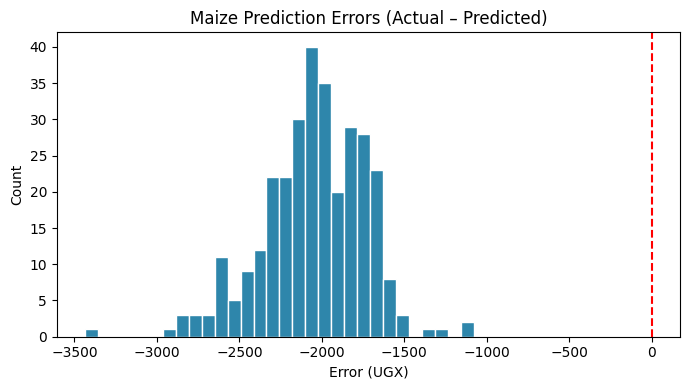

In [3]:
pred_all_m = loaded_m['pipeline'].predict(test_m[loaded_m['features']])
errors_m = test_m['maize_price'].values - pred_all_m
plt.figure(figsize=(7, 4))
plt.hist(errors_m, bins=30, color='#2E86AB', edgecolor='white')
plt.axvline(0, color='red', ls='--')
plt.title('Maize Prediction Errors (Actual – Predicted)')
plt.xlabel('Error (UGX)'); plt.ylabel('Count')
plt.tight_layout()
plt.savefig('../figures/06_maize_error_hist.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 6.4 – Graph 2: Error distribution for beans


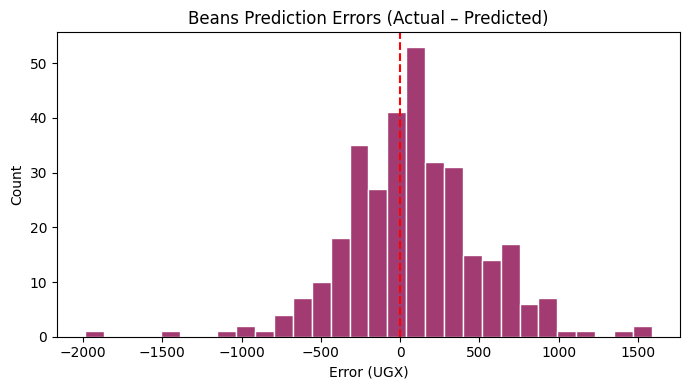

In [4]:
pred_all_b = loaded_b['pipeline'].predict(test_b[loaded_b['features']])
errors_b = test_b['beans_price'].values - pred_all_b
plt.figure(figsize=(7, 4))
plt.hist(errors_b, bins=30, color='#A23B72', edgecolor='white')
plt.axvline(0, color='red', ls='--')
plt.title('Beans Prediction Errors (Actual – Predicted)')
plt.xlabel('Error (UGX)'); plt.ylabel('Count')
plt.tight_layout()
plt.savefig('../figures/06_beans_error_hist.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 6.5 – Graph 3: MAE by market (maize)


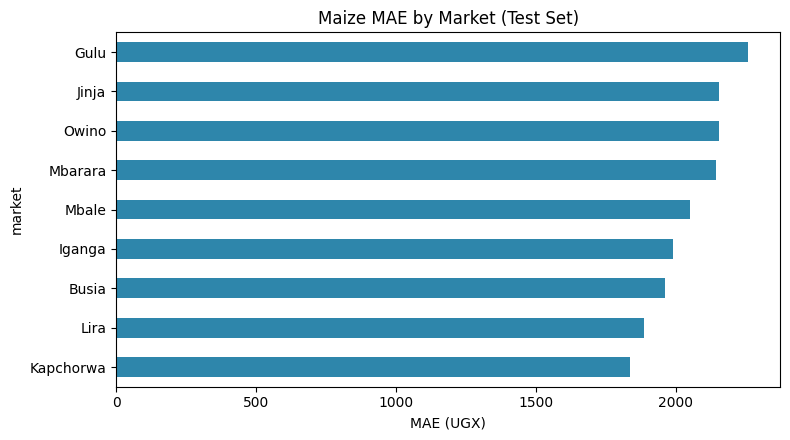

In [5]:
test_m = test_m.copy()
test_m['pred'] = pred_all_m
test_m['abs_err'] = np.abs(test_m['maize_price'] - test_m['pred'])
mae_by_mkt = test_m.groupby('market')['abs_err'].mean().sort_values()
plt.figure(figsize=(8, 4.5))
mae_by_mkt.plot(kind='barh', color='#2E86AB')
plt.title('Maize MAE by Market (Test Set)')
plt.xlabel('MAE (UGX)')
plt.tight_layout()
plt.savefig('../figures/06_maize_mae_by_market.png', dpi=120, bbox_inches='tight')
plt.show()
